# 05 · Regularization

This notebook compares a baseline CNN with L2 weight penalties and dropout. The goal is to see how these choices affect validation learning and held-out test performance.


In [1]:
import matplotlib.pyplot as plt

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.models import create_cnn
from src.training import compile_model, fit_and_evaluate


I0000 00:00:1790113042.143662  119940 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790113042.197338  119940 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790113044.096242  119940 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Prepare the data

Load and normalize the same train and test images for all three model variants.


In [2]:
X_train, y_train, writers_train, X_test, y_test, writers_test = load_emnist()

X_train = preprocess_images(X_train)
X_test = preprocess_images(X_test)

## Define the comparisons

The experiment settings change one regularization choice at a time: no regularization, an L2 penalty, or dropout.


In [3]:
experiments = {
    "Baseline": {
        "dropout_rate": 0.0,
        "l2_strength": 0.0
    },

    "L2": {
        "dropout_rate": 0.0,
        "l2_strength": 1e-4
    },

    "Dropout": {
        "dropout_rate": 0.5,
        "l2_strength": 0.0
    }
}

## Train and evaluate

Each configuration uses the same optimizer, validation split, epoch limit, and batch size. The plots compare training and validation loss and accuracy.


In [4]:
results = {}

for name, params in experiments.items():
    print(f"\n{'='*20} {name} {'='*20}")

    model = compile_model(create_cnn(**params), learning_rate=0.001)
    result = fit_and_evaluate(
        model, X_train, y_train, X_test, y_test,
        epochs=10, batch_size=128, verbose=1,
    )
    results[name] = result
    print(f"Test accuracy: {result['test_accuracy']:.4f}")



==================== Baseline ====================


W0000 00:00:1790113046.236412  119940 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 35s 20ms/step - accuracy: 0.9748 - loss: 0.0864 - val_accuracy: 0.9898 - val_loss: 0.0329
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 37s 22ms/step - accuracy: 0.9919 - loss: 0.0269 - val_accuracy: 0.9918 - val_loss: 0.0271
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 35s 21ms/step - accuracy: 0.9942 - loss: 0.0195 - val_accuracy: 0.9922 - val_loss: 0.0253
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 35s 21ms/step - accuracy: 0.9955 - loss: 0.0154 - val_accuracy: 0.9936 - val_loss: 0.0225
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 35s 20ms/step - accuracy: 0.9965 - loss: 0.0119 - val_accuracy: 0.9930 - val_loss: 0.0258
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 35s 21ms/step - accuracy: 0.9973 - loss: 0.0092 - val_accuracy: 0.9942 - val_loss: 0.0230
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.9978 - loss: 0.0071 - val_accuracy: 0.9934 - val_loss: 0.0253
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 32s 19ms/step - accuracy: 0.9982 -

In [5]:
for name, result in results.items():
    print(
        f"{name:12s} "
        f"accuracy = {result['test_accuracy']:.4f}, "
        f"loss = {result['test_loss']:.4f}"
    )

Baseline     accuracy = 0.9946, loss = 0.0224
L2           accuracy = 0.9937, loss = 0.0369
Dropout      accuracy = 0.9957, loss = 0.0176


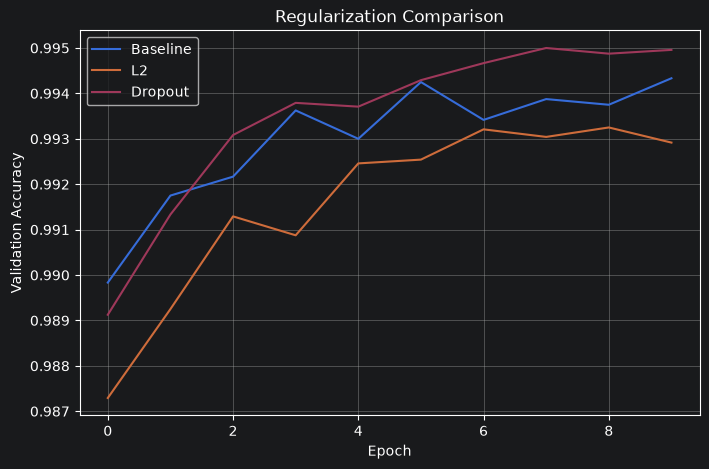

In [6]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    plt.plot(
        result["history"].history["val_accuracy"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Regularization Comparison")
plt.legend()
plt.grid(True)

plt.show()

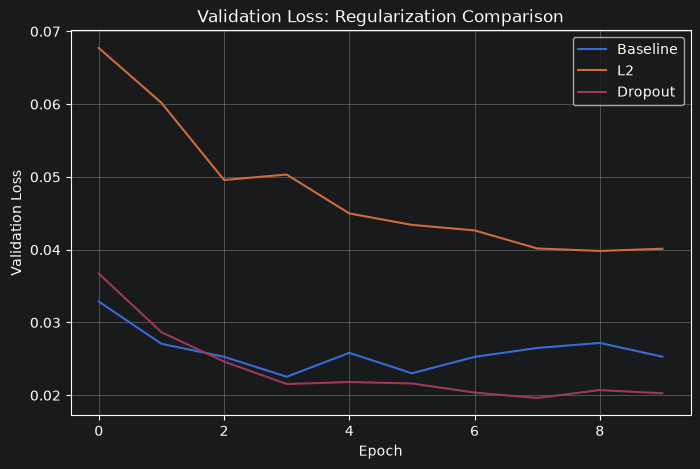

In [7]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    history = result["history"]
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss: Regularization Comparison")
plt.legend()
plt.grid(True)
plt.show()

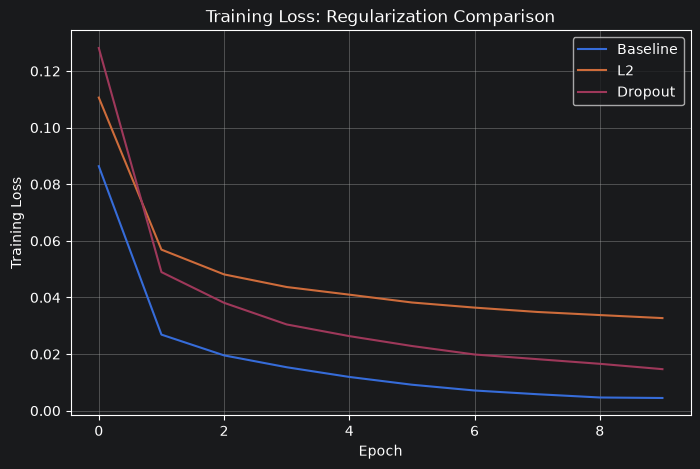

In [8]:
plt.figure(figsize=(8, 5))

for name, result in results.items():
    history = result["history"]
    plt.plot(
        history.history["loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss: Regularization Comparison")
plt.legend()
plt.grid(True)
plt.show()

## Results

In the saved run, the baseline reached **99.46% test accuracy** with **0.0224 loss**. L2 regularization at **1e-4** reached **99.37%** with **0.0369 loss**, so it did not improve on the baseline here. Dropout at **0.5** had the highest accuracy, **99.57%**, and the lowest loss, **0.0176**. Its accuracy gain over the baseline was small: **0.11 percentage points**.

These are results from one run. The notebook compares configurations using the supplied test split, so treat the ranking as exploratory rather than as a final model-selection result. Notebook 08 uses a writer-grouped validation set for that purpose.
